# 11 - Modelos de aprendizaje de máquina (MLlib)

| Técnica | Tipo | Pregunta de negocio |
|---|---|---|
| Gradient-Boosted Trees y Random Forest (regresión logística como referencia) | Supervisado | ¿En qué celdas barrio × franja conviene poner el control esta noche? (P9) |
| Perceptrón multicapa (bono de aprendizaje profundo) | Supervisado | Lo mismo, para comparar con los árboles |
| K-Means | No supervisado | ¿Qué tipo de intervención necesita cada barrio? |

En el modelo supervisado solo entran variables que se conocen antes de que empiece la franja, o sea el lugar, la hora, el día, el calendario, el clima y la historia de las noches anteriores. La causa, los vehículos y las víctimas quedan por fuera.

La partición es por fechas. Entrenamos con 2021 a 2024, elegimos parámetros y modelo con 2025 y evaluamos con enero a mayo de 2026, datos que no se usan para entrenar ni para elegir.

El modelo se entrena y se evalúa con el clima observado. En la operación usaría un pronóstico, que se equivoca, así que su desempeño real podría ser menor.

Como línea base ordenamos las celdas por sus choques del año anterior. El modelo tiene que ganarle para que valga la pena usarlo.

In [1]:
import ast
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import (GBTClassifier, LogisticRegression, MultilayerPerceptronClassifier,
                                       RandomForestClassifier)
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.feature import OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.stat import Correlation
from pyspark.sql import functions as F

import geo
import noche
from config import GOLD_FINAL, SILVER_FINAL, sesion
from decisiones import (FRANJAS_NOCHE, K_RANGO, MODELO_FIN_ENTRENAMIENTO, MODELO_FIN_PRUEBA, MODELO_FIN_VALIDACION, MODELO_INICIO,
                        OBJETIVO, PREVALENCIA_MINIMA, SEMILLA, SEMILLAS, TOP_CELDAS, UMBRAL_CORRELACION)
from estilo import CATEGORICA, TINTA_SECUNDARIA, dec, guardar

spark = sesion("11_modelos")
sc = spark.sparkContext
ACENTO, GRIS = CATEGORICA[0], "#b8b7b1"
tiempos = []                    # tiempo de cada entrenamiento (evidencia del numeral 5)

def cronometrar(nombre, funcion):
    t0 = time.time()
    salida = funcion()
    tiempos.append({"entrenamiento": nombre, "segundos": round(time.time() - t0, 1)})
    return salida

panel = spark.read.parquet(f"{GOLD_FINAL}/panel_noche").filter(F.col("fecha_noche").between(MODELO_INICIO, MODELO_FIN_PRUEBA))
print("Celdas en el periodo del modelo:", f"{panel.count():,}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/22 14:58:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Celdas en el periodo del modelo: 326,040


## 1. Variable objetivo

In [2]:
entrenamiento_crudo = panel.filter(F.col("fecha_noche") <= MODELO_FIN_ENTRENAMIENTO)
prev = entrenamiento_crudo.agg(F.avg("obj_ksi").alias("ksi"), F.avg("obj_lesion").alias("lesion")).first()
print(f"Prevalencia en entrenamiento: KSI {100 * prev['ksi']:.2f} % | con lesionados {100 * prev['lesion']:.2f} %")
if OBJETIVO == "auto":
    OBJ = "obj_ksi" if prev["ksi"] >= PREVALENCIA_MINIMA else "obj_lesion"
else:
    OBJ = f"obj_{OBJETIVO}"
DESCRIPCION_OBJ = {"obj_ksi": "al menos un choque con un muerto o lesionado serio",
                   "obj_lesion": "al menos un choque con lesionados"}[OBJ]
print(f"Objetivo elegido: {OBJ} ({DESCRIPCION_OBJ})")

Prevalencia en entrenamiento: KSI 1.23 % | con lesionados 13.39 %
Objetivo elegido: obj_ksi (al menos un choque con un muerto o lesionado serio)


## 2. Variables candidatas y datos faltantes

Las celdas sin clima se sacan del modelo sin imputar, y reportamos cuántas son y cuál es su tasa del objetivo.

In [3]:
v = max(int(c.split("_")[-1]) for c in panel.columns if c.startswith("ksi_previos_"))
NUMERICAS_CANDIDATAS = [
    # historia del barrio y de la franja (orden = prioridad de negocio para desempatar correlaciones)
    f"ksi_franja_previos_{v}", f"lesion_franja_previos_{v}", f"ksi_previos_{v}", "ksi_previos_28",
    f"lesion_previos_{v}", "lesion_previos_28", f"alcvel_previos_{v}", "alcvel_previos_28",
    # control reciente
    f"dwi_previos_{v}", "dwi_previos_28", f"transito_previos_{v}", "transito_previos_28",
    # clima de la franja
    "precipitacion_mm", "llueve", "nieva", "temperatura", "viento_kmh",
    # calendario
    "fin_de_semana", "es_festivo", "es_evento", "mes_seno", "mes_coseno",
    # barrio
    "poblacion_2020", "densidad_km2",
]
CATEGORICAS = ["puma", "franja", "dia_noche"]

datos = (panel
    .withColumn("mes_seno", F.sin(2 * np.pi * F.col("mes") / 12))
    .withColumn("mes_coseno", F.cos(2 * np.pi * F.col("mes") / 12))
    .withColumn("franja", F.col("franja").cast("string"))
    .withColumn("periodo", F.when(F.col("fecha_noche") <= MODELO_FIN_ENTRENAMIENTO, "entrenamiento")
                            .when(F.col("fecha_noche") <= MODELO_FIN_VALIDACION, "validacion").otherwise("prueba"))
    .withColumn("y", F.col(OBJ).cast("double")))
for c in ["llueve", "nieva", "fin_de_semana", "es_festivo", "es_evento"]:
    datos = datos.withColumn(c, F.col(c).cast("double"))

# Una celda queda fuera si le falta cualquier variable numérica (en la práctica, el clima de alguna hora)
from functools import reduce
incompleta = reduce(lambda a, b: a | b, [F.col(c).isNull() | F.isnan(c) for c in NUMERICAS_CANDIDATAS])
r = datos.filter(incompleta).agg(F.count("*").alias("n"), F.avg("y").alias("tasa")).first()
print(f"Celdas con alguna variable vacía: {r['n']:,} (tasa del objetivo {100 * (r['tasa'] or 0):.2f} % "
      f"frente a {100 * prev[OBJ[4:]]:.2f} %). Se excluyen, no se imputan.")
# pocas particiones: con el panel partido por año cada nivel de cada árbol lanzaba decenas de tareas diminutas
datos = datos.filter(~incompleta).repartition(sc.defaultParallelism).cache()

26/11/22 14:58:44 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Celdas con alguna variable vacía: 0 (tasa del objetivo 0.00 % frente a 1.23 %). Se excluyen, no se imputan.


## 3. Preparación (numeral 4 de la entrega final)

### 4a. Variables muy correlacionadas
Calculamos la correlación de Pearson con MLlib sobre el entrenamiento. De cada pareja con |r| ≥ 0,8 quitamos la de menor prioridad de negocio, según el orden de la lista de arriba.

  lesion_previos_364 ~ alcvel_previos_364: r = 0.81 -> se elimina alcvel_previos_364
  transito_previos_364 ~ transito_previos_28: r = 0.87 -> se elimina transito_previos_28
Se eliminan 2; quedan 22 numéricas + 3 categóricas


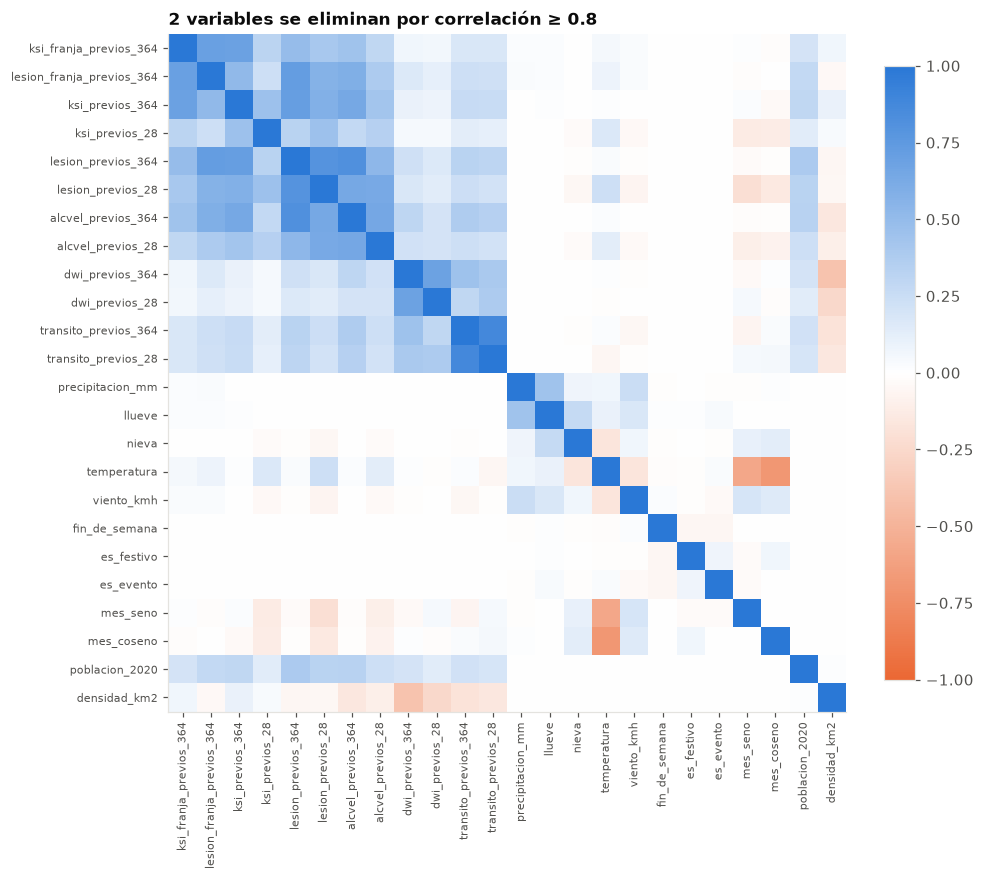

In [4]:
ensamblador_corr = VectorAssembler(inputCols=NUMERICAS_CANDIDATAS, outputCol="v")
entrenamiento = datos.filter(F.col("periodo") == "entrenamiento")
matriz = Correlation.corr(ensamblador_corr.transform(entrenamiento).select("v"), "v").head()[0].toArray()
corr = pd.DataFrame(matriz, index=NUMERICAS_CANDIDATAS, columns=NUMERICAS_CANDIDATAS)
corr.round(3).to_csv("../figuras/tabla_11_correlacion.csv")

eliminadas = []
for i, a in enumerate(NUMERICAS_CANDIDATAS):
    if a in eliminadas:
        continue
    for b in NUMERICAS_CANDIDATAS[i + 1:]:
        if b not in eliminadas and abs(corr.loc[a, b]) >= UMBRAL_CORRELACION:
            eliminadas.append(b)
            print(f"  {a} ~ {b}: r = {corr.loc[a, b]:.2f} -> se elimina {b}")
NUMERICAS = [c for c in NUMERICAS_CANDIDATAS if c not in eliminadas]
print(f"Se eliminan {len(eliminadas)}; quedan {len(NUMERICAS)} numéricas + {len(CATEGORICAS)} categóricas")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr.values, cmap=LinearSegmentedColormap.from_list("d", [CATEGORICA[1], "white", ACENTO]), vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04)
ax.set_title(f"{len(eliminadas)} variables se eliminan por correlación ≥ {UMBRAL_CORRELACION}", fontsize=11)
guardar(fig, "11_01_correlacion")
plt.show()

### 4b y 4c. Normalización y variables finales

- Los árboles no necesitan normalización y reciben las categóricas como índices, con `maxBins` de 55 o más para que el barrio quede como categoría.
- La regresión logística y la red neuronal reciben las categóricas en one-hot y las numéricas estandarizadas con `StandardScaler`, que se ajusta solo con el entrenamiento.

In [5]:
RAZON = {
    "ksi_franja": "Riesgo histórico de esa misma franja en ese barrio", "lesion_franja": "Volumen histórico de esa franja",
    "ksi_previos": "Riesgo reciente del barrio", "lesion_previos": "Volumen reciente del barrio",
    "alcvel_previos": "Choques recientes con alcohol o velocidad", "dwi_previos": "Control reciente: arrestos por embriaguez",
    "transito_previos": "Control reciente: arrestos de tránsito", "precipitacion": "Lluvia prevista", "llueve": "Lluvia prevista",
    "nieva": "Nieve prevista", "temperatura": "Temperatura prevista", "viento": "Viento previsto",
    "fin_de_semana": "Noches de viernes y sábado", "es_festivo": "Festivo", "es_evento": "Noche de evento",
    "mes_": "Estacionalidad (mes en forma circular)", "poblacion": "Tamaño del barrio", "densidad": "Densidad del barrio",
    "puma": "Barrio", "franja": "Franja nocturna (21-23, 00-02, 03-05)", "dia_noche": "Día en que empieza la noche"}
finales = pd.DataFrame([{"variable": c, "tipo": "categórica" if c in CATEGORICAS else "numérica",
                         "razon_de_negocio": next(t for k, t in RAZON.items() if c.startswith(k)),
                         "se_conoce_antes_de_la_franja": "sí"} for c in NUMERICAS + CATEGORICAS])
finales.to_csv("../figuras/tabla_11_variables_finales.csv", index=False)
finales

,variable,tipo,razon_de_negocio,se_conoce_antes_de_la_franja
0,ksi_franja_previos_364,numérica,Riesgo histórico de esa misma franja en ese ba...,sí
1,lesion_franja_previos_364,numérica,Volumen histórico de esa franja,sí
2,ksi_previos_364,numérica,Riesgo reciente del barrio,sí
3,ksi_previos_28,numérica,Riesgo reciente del barrio,sí
4,lesion_previos_364,numérica,Volumen reciente del barrio,sí
5,lesion_previos_28,numérica,Volumen reciente del barrio,sí
6,alcvel_previos_28,numérica,Choques recientes con alcohol o velocidad,sí
7,dwi_previos_364,numérica,Control reciente: arrestos por embriaguez,sí
8,dwi_previos_28,numérica,Control reciente: arrestos por embriaguez,sí
9,transito_previos_364,numérica,Control reciente: arrestos de tránsito,sí


In [6]:
indexadores = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CATEGORICAS]
onehot = OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEGORICAS], outputCols=[f"{c}_oh" for c in CATEGORICAS])
asm_num = VectorAssembler(inputCols=NUMERICAS, outputCol="num")
escalador = StandardScaler(inputCol="num", outputCol="num_esc", withMean=True, withStd=True)
asm_lineal = VectorAssembler(inputCols=["num_esc"] + [f"{c}_oh" for c in CATEGORICAS], outputCol="features")
asm_arbol = VectorAssembler(inputCols=NUMERICAS + [f"{c}_idx" for c in CATEGORICAS], outputCol="features")
ETAPAS_LINEAL = indexadores + [onehot, asm_num, escalador, asm_lineal]
ETAPAS_ARBOL = indexadores + [asm_arbol]

# Peso por clase: compensa que las celdas positivas sean pocas
n_tot, n_pos = entrenamiento.count(), entrenamiento.agg(F.sum("y")).first()[0]
w_pos, w_neg = n_tot / (2 * n_pos), n_tot / (2 * (n_tot - n_pos))
datos = datos.withColumn("peso", F.when(F.col("y") == 1, w_pos).otherwise(w_neg))
entrenamiento = datos.filter(F.col("periodo") == "entrenamiento").cache()
validacion = datos.filter(F.col("periodo") == "validacion").cache()
prueba = datos.filter(F.col("periodo") == "prueba").cache()
particion = pd.DataFrame([{"conjunto": n, "desde": d.agg(F.min("fecha_noche")).first()[0], "hasta": d.agg(F.max("fecha_noche")).first()[0],
                           "celdas": d.count(), "prevalencia_%": round(100 * d.agg(F.avg("y")).first()[0], 2)}
                          for n, d in [("entrenamiento", entrenamiento), ("validación", validacion), ("prueba", prueba)]])
particion.to_csv("../figuras/tabla_11_particion.csv", index=False)
print(f"Pesos: positivo {w_pos:.2f}, negativo {w_neg:.2f}")
particion

Pesos: positivo 40.52, negativo 0.51


,conjunto,desde,hasta,celdas,prevalencia_%
0,entrenamiento,2021-01-01,2024-12-31,241065,1.23
1,validación,2025-01-01,2025-12-31,60225,1.25
2,prueba,2026-01-01,2026-05-30,24750,0.95


## 4. Métricas

| Métrica | Por qué | Lectura para la institución |
|---|---|---|
| Captura en el 10 % superior | Métrica de negocio principal | Parte de las celdas con un caso que se cubre al controlar el 10 % que marca el modelo |
| AUC-PR | Sirve cuando la clase es rara, con ella se eligen los parámetros | Calidad del orden entre las celdas de más riesgo |
| AUC-ROC | Comparable con la literatura | Probabilidad de ordenar bien un par |
| Brier y calibración | Para saber si el puntaje sirve como probabilidad | Los pesos por clase lo inflan, por eso solo lo usamos para ordenar |

Las métricas se calculan con las funciones de `noche.py`, que probamos contra scikit-learn en `tests/probar_noche.py`.

In [7]:
prob1 = vector_to_array(F.col("probability"))[1]

def puntuar(modelo, df):
    return modelo.transform(df).select("puma", "fecha_noche", "franja", "y", prob1.alias("p")).toPandas()

def metricas(y, p, nombre):
    y, p = np.asarray(y), np.asarray(p)
    return {"modelo": nombre, "AUC-ROC": noche.auc_roc(y, p), "AUC-PR": noche.auc_pr(y, p),
            "captura_5%": noche.captura_top(y, p, 0.05), "captura_10%": noche.captura_top(y, p, TOP_CELDAS),
            "captura_20%": noche.captura_top(y, p, 0.20), "Brier": float(np.mean((p - y) ** 2)), "prevalencia": y.mean()}

def linea_base(df):
    """Orden que haría un analista sin modelo: choques del objetivo en esa franja y barrio el último año."""
    col = f"ksi_franja_previos_{v}" if OBJ == "obj_ksi" else f"lesion_franja_previos_{v}"
    d = df.select("y", col, f"lesion_franja_previos_{v}").toPandas()
    return d["y"].values, (d[col] + 1e-6 * d[f"lesion_franja_previos_{v}"]).values   # desempate por volumen

## 5. Pruebas de parámetros (validación 2025)

In [8]:
REJILLA = {
    "Regresión logística": [{"regParam": r, "elasticNetParam": e} for r in [0.0, 0.01] for e in [0.0, 0.5]],
    "Random Forest": [{"numTrees": 40, "maxDepth": 6}, {"numTrees": 80, "maxDepth": 6}, {"numTrees": 40, "maxDepth": 9}],
    "Gradient-Boosted Trees": [{"maxIter": 30, "maxDepth": 4, "stepSize": 0.1}, {"maxIter": 60, "maxDepth": 4, "stepSize": 0.05},
                               {"maxIter": 30, "maxDepth": 5, "stepSize": 0.1}],
}

def construir(tecnica, params):
    if tecnica == "Regresión logística":
        return Pipeline(stages=ETAPAS_LINEAL + [LogisticRegression(featuresCol="features", labelCol="y", weightCol="peso",
                                                                   maxIter=100, **params)])
    if tecnica == "Random Forest":
        return Pipeline(stages=ETAPAS_ARBOL + [RandomForestClassifier(featuresCol="features", labelCol="y", weightCol="peso",
                                                                      maxBins=64, seed=SEMILLA, **params)])
    return Pipeline(stages=ETAPAS_ARBOL + [GBTClassifier(featuresCol="features", labelCol="y", weightCol="peso",
                                                         maxBins=64, seed=SEMILLA, **params)])

pruebas = []
for tecnica, combinaciones in REJILLA.items():
    for params in combinaciones:
        etiqueta = f"{tecnica} {params}"
        modelo = cronometrar(etiqueta, lambda: construir(tecnica, params).fit(entrenamiento))
        val = puntuar(modelo, validacion)
        m = metricas(val["y"], val["p"], tecnica)
        pruebas.append({"tecnica": tecnica, "parametros": str(params), **{k: m[k] for k in ["AUC-PR", "AUC-ROC", "captura_10%"]}})
        print(f"{etiqueta:<75} AUC-PR {m['AUC-PR']:.4f} | captura 10 % {m['captura_10%']:.3f}")
pruebas = pd.DataFrame(pruebas)
y_val, base_val = linea_base(validacion)
mb = metricas(y_val, base_val, "Línea base")
print(f"\nLínea base en validación: AUC-PR {mb['AUC-PR']:.4f} | captura 10 % {mb['captura_10%']:.3f}")
pruebas.round(4).to_csv("../figuras/tabla_11_pruebas_parametros.csv", index=False)
mejores = pruebas.loc[pruebas.groupby("tecnica")["AUC-PR"].idxmax()]
mejores

26/11/22 14:59:25 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


Regresión logística {'regParam': 0.0, 'elasticNetParam': 0.0}               AUC-PR 0.0213 | captura 10 % 0.204


Regresión logística {'regParam': 0.0, 'elasticNetParam': 0.5}               AUC-PR 0.0213 | captura 10 % 0.204


Regresión logística {'regParam': 0.01, 'elasticNetParam': 0.0}              AUC-PR 0.0214 | captura 10 % 0.211


Regresión logística {'regParam': 0.01, 'elasticNetParam': 0.5}              AUC-PR 0.0217 | captura 10 % 0.211


Random Forest {'numTrees': 40, 'maxDepth': 6}                               AUC-PR 0.0220 | captura 10 % 0.201


... (8 outputs left out)

Gradient-Boosted Trees {'maxIter': 60, 'maxDepth': 4, 'stepSize': 0.05}     AUC-PR 0.0202 | captura 10 % 0.185


Gradient-Boosted Trees {'maxIter': 30, 'maxDepth': 5, 'stepSize': 0.1}      AUC-PR 0.0189 | captura 10 % 0.176



Línea base en validación: AUC-PR 0.0174 | captura 10 % 0.169


,tecnica,parametros,AUC-PR,AUC-ROC,captura_10%
8,Gradient-Boosted Trees,"{'maxIter': 60, 'maxDepth': 4, 'stepSize': 0.05}",0.020172,0.636681,0.185333
4,Random Forest,"{'numTrees': 40, 'maxDepth': 6}",0.022016,0.647826,0.201333
3,Regresión logística,"{'regParam': 0.01, 'elasticNetParam': 0.5}",0.021682,0.654723,0.210667


## 6. Evaluación final en la prueba (enero-mayo 2026)

Cada técnica se reentrena con su mejor combinación sobre entrenamiento y validación, y se evalúa en la prueba. La evaluación se repitió una vez porque en la primera corrida quedó mal la población de algunos barrios (notebook 07). Al repetirla no cambiamos rejillas, variables ni reglas de elección.

In [9]:
ent_val = entrenamiento.unionByName(validacion).cache()
finales_modelos, resultados, puntajes = {}, [], {}
for _, fila in mejores.iterrows():
    params = ast.literal_eval(fila["parametros"])
    modelo = cronometrar(f"{fila['tecnica']} final", lambda: construir(fila["tecnica"], params).fit(ent_val))
    finales_modelos[fila["tecnica"]] = modelo
    pr = puntuar(modelo, prueba)
    puntajes[fila["tecnica"]] = pr
    resultados.append(metricas(pr["y"], pr["p"], fila["tecnica"]))
y_te, base_te = linea_base(prueba)
resultados.append({**metricas(y_te, base_te, "Línea base (año anterior)"), "Brier": float("nan")})   # son conteos, no probabilidades

### Bono: perceptrón multicapa

La red recibe la misma entrada que la regresión logística (numéricas estandarizadas y categóricas en one-hot). Como esta clase de MLlib no admite pesos por observación, la entrenamos con una muestra balanceada, con todos los positivos y otros tantos negativos, y la evaluamos sobre la prueba sin balancear.

In [10]:
def balancear(df, semilla=SEMILLA):
    pos = df.filter("y = 1")
    neg = df.filter("y = 0")
    frac = min(1.0, pos.count() / neg.count())
    return pos.unionByName(neg.sample(False, frac, seed=semilla))

preparador = Pipeline(stages=ETAPAS_LINEAL).fit(entrenamiento)
n_entrada = len(preparador.transform(entrenamiento.limit(1)).select("features").first()[0])
ARQUITECTURAS = [[n_entrada, 16, 2], [n_entrada, 32, 16, 2]]
pruebas_mlp = []
ent_bal = preparador.transform(balancear(entrenamiento)).cache()
val_prep = preparador.transform(validacion)
for capas in ARQUITECTURAS:
    for iteraciones in [50, 100]:
        mlp = MultilayerPerceptronClassifier(featuresCol="features", labelCol="y", layers=capas, maxIter=iteraciones,
                                             blockSize=128, seed=SEMILLA)
        modelo = cronometrar(f"MLP {capas} it={iteraciones}", lambda: mlp.fit(ent_bal))
        val = modelo.transform(val_prep).select("y", prob1.alias("p")).toPandas()
        m = metricas(val["y"], val["p"], "MLP")
        pruebas_mlp.append({"tecnica": "Red neuronal (MLP)", "parametros": str({"layers": capas, "maxIter": iteraciones}),
                            "AUC-PR": m["AUC-PR"], "AUC-ROC": m["AUC-ROC"], "captura_10%": m["captura_10%"]})
        print(f"MLP {str(capas):<22} it={iteraciones:<4} AUC-PR {m['AUC-PR']:.4f} | captura 10 % {m['captura_10%']:.3f}")
pruebas_mlp = pd.DataFrame(pruebas_mlp)
pd.concat([pruebas, pruebas_mlp]).round(4).to_csv("../figuras/tabla_11_pruebas_parametros.csv", index=False)

mejor_mlp = ast.literal_eval(pruebas_mlp.loc[pruebas_mlp["AUC-PR"].idxmax(), "parametros"])
preparador_f = Pipeline(stages=ETAPAS_LINEAL).fit(ent_val)
mlp_final = cronometrar("MLP final", lambda: MultilayerPerceptronClassifier(
    featuresCol="features", labelCol="y", blockSize=128, seed=SEMILLA, **mejor_mlp).fit(preparador_f.transform(balancear(ent_val))))
pr = mlp_final.transform(preparador_f.transform(prueba)).select("puma", "fecha_noche", "franja", "y", prob1.alias("p")).toPandas()
puntajes["Red neuronal (MLP)"] = pr
finales_modelos["Red neuronal (MLP)"] = PipelineModel(stages=preparador_f.stages + [mlp_final])
resultados.append(metricas(pr["y"], pr["p"], "Red neuronal (MLP)"))

evaluacion = pd.DataFrame(resultados).set_index("modelo")
evaluacion.round(4).to_csv("../figuras/tabla_11_evaluacion_prueba.csv")
evaluacion.round(4)

MLP [87, 16, 2]            it=50   AUC-PR 0.0186 | captura 10 % 0.175


MLP [87, 16, 2]            it=100  AUC-PR 0.0165 | captura 10 % 0.140


MLP [87, 32, 16, 2]        it=50   AUC-PR 0.0210 | captura 10 % 0.203


MLP [87, 32, 16, 2]        it=100  AUC-PR 0.0170 | captura 10 % 0.149


,AUC-ROC,AUC-PR,captura_5%,captura_10%,captura_20%,Brier,prevalencia
modelo,,,,,,,
Gradient-Boosted Trees,0.6561,0.0158,0.0894,0.1915,0.3745,0.1866,0.0095
Random Forest,0.6610,0.0160,0.0681,0.1957,0.3915,0.1965,0.0095
Regresión logística,0.6614,0.0155,0.0787,0.1915,0.3489,0.2003,0.0095
Línea base (año anterior),0.6030,0.0135,0.1106,0.1809,0.3021,NaN,0.0095
Red neuronal (MLP),0.6288,0.0141,0.0894,0.1447,0.3064,0.2210,0.0095


Mejor modelo: Random Forest. Captura en el 10 % superior: 19.6 % frente a 18.1 % de la línea base.
COMPUERTA G3: SUPERADA: el modelo aporta frente a la línea base.


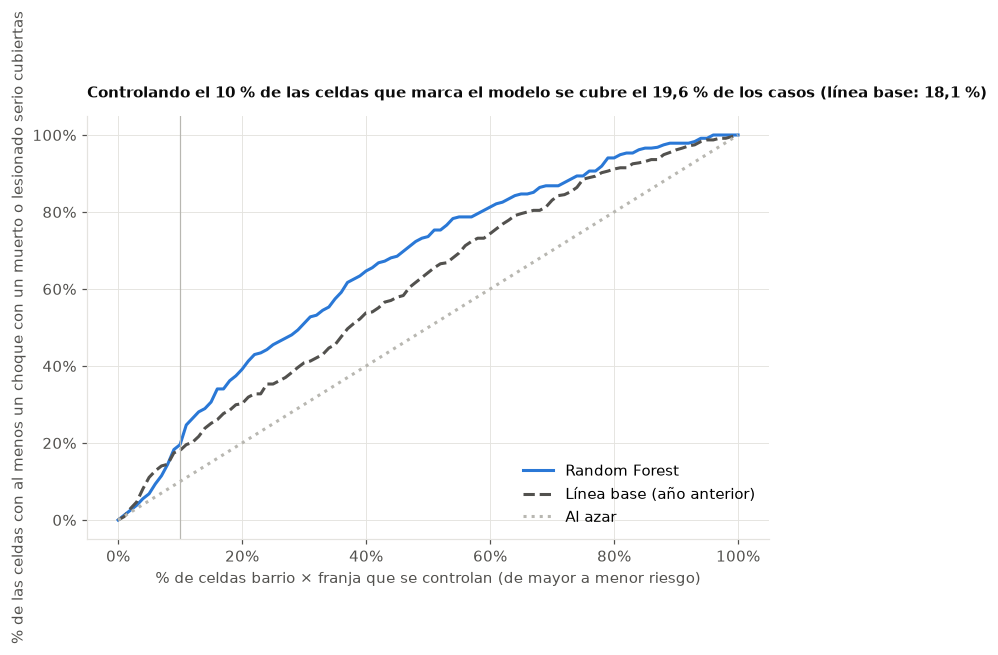

In [11]:
# El modelo se elige con la validación de 2025. La prueba de 2026 solo sirve para evaluarlo.
todas = pd.concat([pruebas, pruebas_mlp], ignore_index=True)
mejor = todas.loc[todas["AUC-PR"].idxmax(), "tecnica"]
pd.DataFrame([{"mejor_modelo": mejor, "elegido_con": "AUC-PR en validación 2025"}]).to_csv("../figuras/tabla_11_modelo_elegido.csv", index=False)
cap_m, cap_b = evaluacion.loc[mejor, "captura_10%"], evaluacion.loc["Línea base (año anterior)", "captura_10%"]
print(f"Mejor modelo: {mejor}. Captura en el 10 % superior: {100 * cap_m:.1f} % frente a {100 * cap_b:.1f} % de la línea base.")
supera = (evaluacion.loc[mejor, "AUC-PR"] > evaluacion.loc["Línea base (año anterior)", "AUC-PR"]) and cap_m > cap_b
print("COMPUERTA G3:", "SUPERADA: el modelo aporta frente a la línea base." if supera else
      "NO SUPERADA: se reporta así y la recomendación se apoya en el análisis descriptivo.")

fig, ax = plt.subplots(figsize=(8, 5))
fracciones = np.linspace(0, 1, 101)
for nombre, color, estilo in [(mejor, ACENTO, "-"), ("Línea base (año anterior)", TINTA_SECUNDARIA, "--")]:
    if nombre in puntajes:
        y_, p_ = puntajes[nombre]["y"].values, puntajes[nombre]["p"].values
    else:
        y_, p_ = y_te, base_te
    ax.plot(100 * fracciones, [100 * noche.captura_top(y_, p_, f) if f > 0 else 0 for f in fracciones],
            color=color, linestyle=estilo, label=nombre)
ax.plot([0, 100], [0, 100], color=GRIS, linestyle=":", label="Al azar")
ax.axvline(100 * TOP_CELDAS, color=GRIS, linewidth=0.8)
ax.set_xlabel("% de celdas barrio × franja que se controlan (de mayor a menor riesgo)")
ax.set_ylabel(f"% de las celdas con {DESCRIPCION_OBJ} cubiertas")
ax.xaxis.set_major_formatter(PercentFormatter()); ax.yaxis.set_major_formatter(PercentFormatter())
ax.legend(loc="lower right")
ax.set_title(f"Controlando el 10 % de las celdas que marca el modelo se cubre el {dec(100 * cap_m)} % de los casos "
             f"(línea base: {dec(100 * cap_b)} %)", fontsize=10, pad=12)
guardar(fig, "11_02_curva_captura")
plt.show()

Para ver la calibración comparamos, por decil de riesgo, el puntaje medio del modelo con la tasa observada. Los pesos por clase inflan el puntaje. Para ordenar celdas no afecta, pero habría que recalibrarlo antes de presentarlo como probabilidad de un KSI.

In [12]:
pm = puntajes[mejor].copy()
pm["decil"] = pd.qcut(pm["p"].rank(method="first"), 10, labels=False) + 1
calib = pm.groupby("decil").agg(prob_media=("p", "mean"), tasa_observada=("y", "mean"), celdas=("y", "size"))
calib.round(4).to_csv("../figuras/tabla_11_calibracion.csv")
calib.round(4)

,prob_media,tasa_observada,celdas
decil,,,
1,0.2643,0.0020,2475
2,0.3072,0.0036,2475
3,0.3399,0.0069,2475
4,0.3749,0.0053,2475
5,0.4051,0.0073,2475
6,0.4384,0.0085,2475
7,0.4739,0.0129,2475
8,0.5129,0.0113,2475
9,0.5584,0.0186,2475


## 7. ¿Qué usa el modelo? Importancia por permutación

Desordenamos una variable a la vez en la prueba y medimos cuánto cae el AUC-PR. A diferencia de la importancia interna de los árboles, este método no favorece a las variables con muchas categorías, como el barrio. Mide cuánto usa el modelo cada variable, sin decir nada sobre causas.

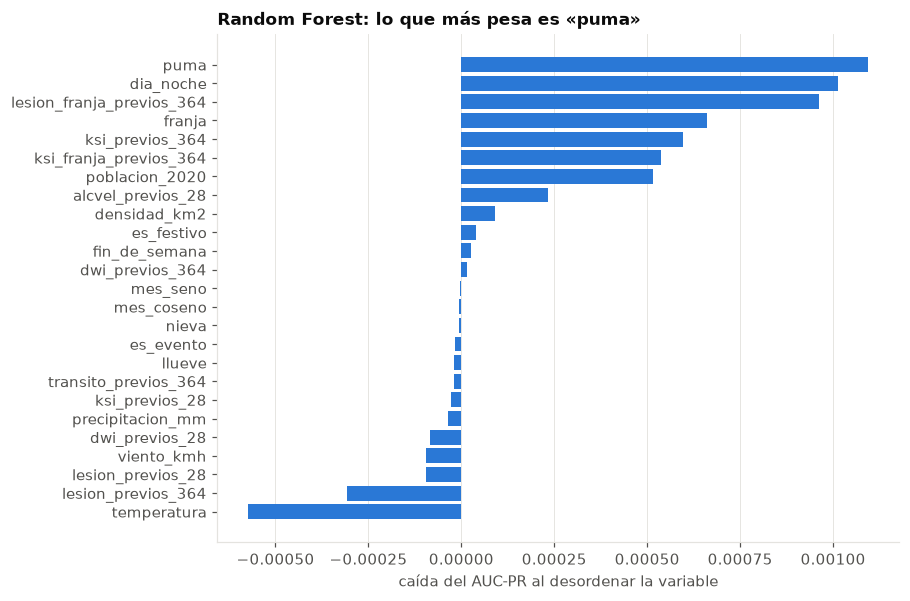

In [13]:
modelo_imp, nombre_imp = finales_modelos[mejor], mejor
columnas = NUMERICAS + CATEGORICAS + ["y"]
prueba_pd = prueba.select(*columnas).toPandas()
esquema = prueba.select(*columnas).schema
base_pr = noche.auc_pr(prueba_pd["y"], modelo_imp.transform(spark.createDataFrame(prueba_pd, esquema)).select(prob1).toPandas().iloc[:, 0])
rng = np.random.default_rng(SEMILLA)
importancias = []
for c in NUMERICAS + CATEGORICAS:
    perm = prueba_pd.copy()
    perm[c] = rng.permutation(perm[c].values)
    p_perm = modelo_imp.transform(spark.createDataFrame(perm, esquema)).select(prob1).toPandas().iloc[:, 0]
    importancias.append({"variable": c, "caida_auc_pr": base_pr - noche.auc_pr(perm["y"], p_perm)})
importancias = pd.DataFrame(importancias).sort_values("caida_auc_pr")
importancias.round(5).to_csv("../figuras/tabla_11_importancia_permutacion.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importancias["variable"], importancias["caida_auc_pr"], color=ACENTO)
ax.set_xlabel("caída del AUC-PR al desordenar la variable")
ax.grid(axis="y", visible=False)
ax.set_title(f"{nombre_imp}: lo que más pesa es «{importancias.iloc[-1]['variable']}»", fontsize=11)
guardar(fig, "11_03_importancia")
plt.show()

## 8. No supervisado: tipología de barrios (K-Means)

Describimos los 55 barrios por su riesgo nocturno, la mezcla de causas, el control, la brecha, la sensibilidad a la lluvia y quiénes son las víctimas. Las tasas van en logaritmo, se quitan las correlaciones de 0,8 o más y se estandariza. La pobreza y la educación no entran porque solo existen por distrito y harían que el algoritmo agrupara por distrito.

Barrios con algún indicador vacío (se excluyen del agrupamiento): []
Eliminadas por correlación: ['tasa_lesion_noche'] | variables finales: ['tasa_ksi_noche', 'pct_alcohol_velocidad', 'tasa_dwi', 'brecha', 'sensibilidad_lluvia', 'pct_ksi_de_noche', 'pct_peatones_ksi_noche']


   silueta  inercia  grupo_mas_pequeno  estabilidad_ARI
k                                                      
2    0.304  297.763                 19            0.520
3    0.328  235.370                  9            0.528
4    0.293  211.942                  3            0.571
5    0.227  203.612                  2            0.303
6    0.269  173.666                  1            0.402
7    0.259  159.564                  2            0.464
8    0.233  152.926                  1            0.406
k elegido: 3


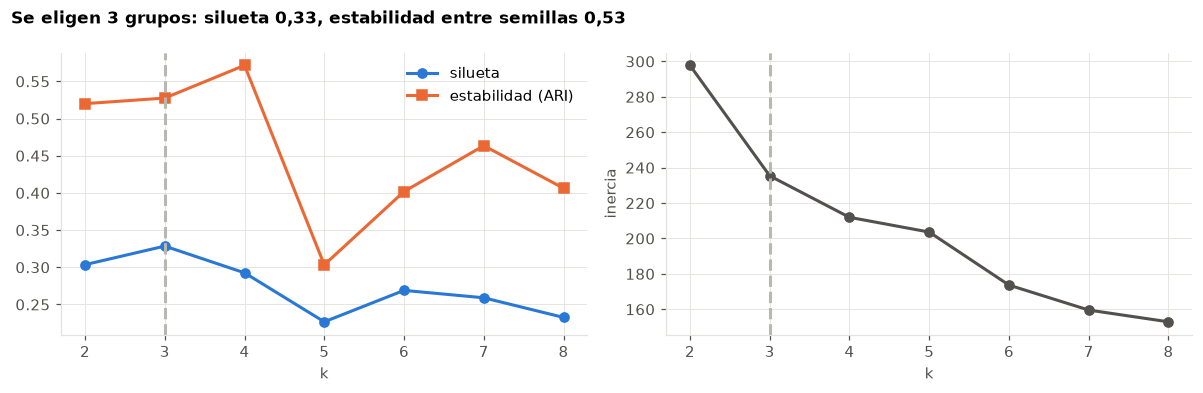

In [14]:
barrios = spark.read.parquet(f"{GOLD_FINAL}/barrios_noche").toPandas().set_index("puma")
CANDIDATAS_K = ["tasa_ksi_noche", "tasa_lesion_noche", "pct_alcohol_velocidad", "tasa_dwi", "brecha",
                "sensibilidad_lluvia", "pct_ksi_de_noche", "pct_peatones_ksi_noche"]
X = barrios[CANDIDATAS_K].copy()
for c in ["tasa_ksi_noche", "tasa_lesion_noche", "tasa_dwi"]:
    X[c] = np.log1p(X[c])
faltan = X.isna().any(axis=1)
print("Barrios con algún indicador vacío (se excluyen del agrupamiento):", list(X.index[faltan]))
X = X[~faltan]
corr_k = X.corr()
fuera = []
for i, a in enumerate(CANDIDATAS_K):
    for b in CANDIDATAS_K[i + 1:]:
        if a not in fuera and b not in fuera and abs(corr_k.loc[a, b]) >= UMBRAL_CORRELACION:
            fuera.append(b)
VARS_K = [c for c in CANDIDATAS_K if c not in fuera]
print("Eliminadas por correlación:", fuera, "| variables finales:", VARS_K)
corr_k.round(3).to_csv("../figuras/tabla_11_correlacion_barrios.csv")

kdf = spark.createDataFrame(X[VARS_K].reset_index())
kdf = StandardScaler(inputCol="v", outputCol="features", withMean=True, withStd=True).fit(
    VectorAssembler(inputCols=VARS_K, outputCol="v").transform(kdf)).transform(VectorAssembler(inputCols=VARS_K, outputCol="v").transform(kdf)).cache()

evaluador = ClusteringEvaluator(featuresCol="features", metricName="silhouette")
corridas = []
etiquetas = {}
for k in K_RANGO:
    for s in SEMILLAS:
        m = KMeans(k=k, seed=s, featuresCol="features", maxIter=100).fit(kdf)
        pred = m.transform(kdf)
        etiquetas[(k, s)] = pred.select("puma", "prediction").toPandas().set_index("puma")["prediction"].sort_index().values
        tam = pred.groupBy("prediction").count().agg(F.min("count")).first()[0]
        corridas.append({"k": k, "semilla": s, "silueta": evaluador.evaluate(pred), "inercia": m.summary.trainingCost,
                         "grupo_mas_pequeno": tam})
corridas = pd.DataFrame(corridas)
estabilidad = {k: np.mean([noche.indice_rand_ajustado(etiquetas[(k, a)], etiquetas[(k, b)])
                           for i, a in enumerate(SEMILLAS) for b in SEMILLAS[i + 1:]]) for k in K_RANGO}
resumen_k = corridas.groupby("k").agg(silueta=("silueta", "mean"), inercia=("inercia", "mean"),
                                      grupo_mas_pequeno=("grupo_mas_pequeno", "min"))
resumen_k["estabilidad_ARI"] = pd.Series(estabilidad)
resumen_k.round(4).to_csv("../figuras/tabla_11_kmeans_pruebas.csv")
print(resumen_k.round(3))

# Regla: entre k >= 3 (dos grupos no distinguen tipos de intervención), el de mayor silueta con
# estabilidad >= 0,8 y sin grupos de un solo barrio. Si ninguno cumple, el de mayor silueta.
candidatos = resumen_k[(resumen_k.index >= 3) & (resumen_k["estabilidad_ARI"] >= 0.8) & (resumen_k["grupo_mas_pequeno"] >= 2)]
K_ELEGIDO = int((candidatos if len(candidatos) else resumen_k[resumen_k.index >= 3])["silueta"].idxmax())
print("k elegido:", K_ELEGIDO)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(resumen_k.index, resumen_k["silueta"], marker="o", color=ACENTO, label="silueta")
axes[0].plot(resumen_k.index, resumen_k["estabilidad_ARI"], marker="s", color=CATEGORICA[1], label="estabilidad (ARI)")
axes[0].axvline(K_ELEGIDO, color=GRIS, linestyle="--"); axes[0].legend(); axes[0].set_xlabel("k")
axes[1].plot(resumen_k.index, resumen_k["inercia"], marker="o", color=TINTA_SECUNDARIA)
axes[1].axvline(K_ELEGIDO, color=GRIS, linestyle="--"); axes[1].set_xlabel("k"); axes[1].set_ylabel("inercia")
fig.suptitle(f"Se eligen {K_ELEGIDO} grupos: silueta {dec(resumen_k.loc[K_ELEGIDO, 'silueta'], 2)}, "
             f"estabilidad entre semillas {dec(resumen_k.loc[K_ELEGIDO, 'estabilidad_ARI'], 2)}", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
fig.tight_layout()
guardar(fig, "11_04_kmeans_eleccion")
plt.show()

In [15]:
modelo_k = cronometrar(f"K-Means k={K_ELEGIDO}", lambda: KMeans(k=K_ELEGIDO, seed=SEMILLA, featuresCol="features", maxIter=100).fit(kdf))
grupos = modelo_k.transform(kdf).select("puma", "prediction").toPandas().set_index("puma")["prediction"]
barrios["grupo"] = grupos
perfil = barrios.dropna(subset=["grupo"]).groupby("grupo").agg(
    barrios=("borough", "size"), poblacion=("poblacion_2020", "sum"),
    **{c: (c, "mean") for c in CANDIDATAS_K})
# Rasgos de cada grupo: variables a más de 0,5 desviaciones del promedio de los barrios
z = (perfil[VARS_K] - barrios[VARS_K].mean()) / barrios[VARS_K].std()
perfil["rasgos"] = [", ".join(f"{'alto' if z.loc[g, c] > 0 else 'bajo'} {c}" for c in VARS_K if abs(z.loc[g, c]) > 0.5) or "cerca del promedio"
                    for g in perfil.index]
perfil["barrios_ejemplo"] = ["; ".join(barrios[barrios["grupo"] == g].sort_values("poblacion_2020", ascending=False)["barrio"].iloc[:4])
                             for g in perfil.index]
perfil.round(2).to_csv("../figuras/tabla_11_kmeans_perfil.csv")
barrios[["barrio", "borough", "grupo"]].to_csv("../figuras/tabla_11_kmeans_barrios.csv")
perfil.round(2)

,barrios,poblacion,tasa_ksi_noche,tasa_lesion_noche,pct_alcohol_velocidad,tasa_dwi,brecha,sensibilidad_lluvia,pct_ksi_de_noche,pct_peatones_ksi_noche,rasgos,barrios_ejemplo
grupo,,,,,,,,,,,,
0,18,2820420,10.96,123.40,23.11,37.38,0.12,1.06,35.86,25.88,"alto tasa_ksi_noche, alto pct_alcohol_velocida...",Canarsie; Queens Village; Soundview-Castle Hil...
1,20,3121525,6.53,82.65,21.18,42.38,-0.38,1.20,28.71,22.92,"bajo tasa_ksi_noche, alto tasa_dwi, bajo brecha",Jamaica; Bensonhurst West; Jackson Heights; We...
2,17,2862245,8.59,102.78,15.44,21.81,0.33,1.22,29.86,32.10,"bajo pct_alcohol_velocidad, bajo tasa_dwi, alt...",Flushing; Lenox Hill-Roosevelt Island; Upper W...


Según la columna `rasgos`, el grupo 0 tiene riesgo nocturno alto con más alcohol y velocidad (rediseño vial y control de velocidad), el 1 tiene riesgo bajo con más control (seguimiento) y el 2 tiene más víctimas peatonales y poco control por embriaguez (cruces e iluminación). Como la estabilidad es de 0,53, los grupos se leen como orientativos.

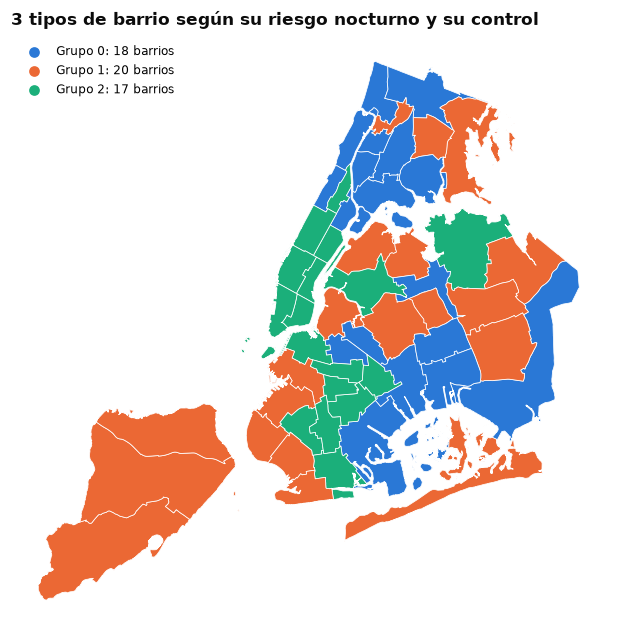

In [16]:
pumas = geo.cargar_pumas(spark)
fig, ax = plt.subplots(figsize=(7, 7))
geo.dibujar_pumas(ax, pumas, {p: CATEGORICA[int(g)] for p, g in grupos.items()})
for g in sorted(grupos.unique()):
    ax.scatter([], [], color=CATEGORICA[int(g)], label=f"Grupo {int(g)}: {int((grupos == g).sum())} barrios")
ax.legend(loc="upper left", fontsize=8)
ax.set_title(f"{K_ELEGIDO} tipos de barrio según su riesgo nocturno y su control", fontsize=11)
guardar(fig, "11_05_kmeans_mapa")
plt.show()

## 9. Cómo se usaría: celdas prioritarias para las próximas noches

Probamos cómo se usaría el modelo con el pronóstico de OpenWeather que guardó el notebook 07. La historia de cada barrio llega hasta mayo de 2026, por eso la lista es un ejemplo de uso y no se debe tomar como predicción para esas fechas.

In [17]:
ruta_pron = f"{SILVER_FINAL}/clima_pronostico"
fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(sc._jsc.hadoopConfiguration())
modelo_op = finales_modelos[mejor]
if fs.exists(spark._jvm.org.apache.hadoop.fs.Path(ruta_pron)):
    pron = spark.read.parquet(ruta_pron).toPandas()
    pron["ts_local"] = pd.to_datetime(pron["ts_local"])
    pron["hora"] = pron["ts_local"].dt.hour
    pron["franja"] = pron["hora"] // 3
    pron["fecha_noche"] = (pron["ts_local"] - pd.to_timedelta((pron["hora"] < 6).astype(int), unit="D")).dt.normalize()
    pron = pron[pron["franja"].isin(FRANJAS_NOCHE)]
    clima_f = pron.groupby(["fecha_noche", "franja"]).agg(temperatura=("temp", "mean"), precipitacion_mm=("lluvia_3h", "sum"),
                                                         nieve=("nieve_3h", "sum"), viento_kmh=("viento_kmh", "mean")).reset_index()
    clima_f["llueve"] = (clima_f["precipitacion_mm"] >= 0.1).astype(float)
    clima_f["nieva"] = (clima_f["nieve"] > 0).astype(float)
    fechas_cal = noche.calendario(int(clima_f["fecha_noche"].dt.year.min()), int(clima_f["fecha_noche"].dt.year.max()) + 1)
    festivos = {f["fecha"] for f in fechas_cal if f["tipo"] == "festivo"}
    eventos = {f["fecha"] for f in fechas_cal if f["tipo"] == "evento"}
    ultima = datos.agg(F.max("fecha_noche")).first()[0]
    historia = datos.filter(F.col("fecha_noche") == ultima).drop("temperatura", "precipitacion_mm", "llueve", "nieva", "viento_kmh",
                                                                 "fecha_noche", "mes_seno", "mes_coseno", "dia_noche",
                                                                 "fin_de_semana", "es_festivo", "es_evento").toPandas()
    filas = []
    for _, cf in clima_f.iterrows():
        h = historia[historia["franja"] == str(int(cf["franja"]))].copy()
        mes = cf["fecha_noche"].month
        dia = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"][cf["fecha_noche"].weekday()]
        h = h.assign(fecha_noche=cf["fecha_noche"].date(), temperatura=cf["temperatura"], precipitacion_mm=cf["precipitacion_mm"],
                     llueve=cf["llueve"], nieva=cf["nieva"], mes_seno=np.sin(2 * np.pi * mes / 12), mes_coseno=np.cos(2 * np.pi * mes / 12),
                     dia_noche=dia, fin_de_semana=float(dia in ("Viernes", "Sábado")), viento_kmh=cf["viento_kmh"],
                     es_festivo=float(cf["fecha_noche"].date() in festivos), es_evento=float(cf["fecha_noche"].date() in eventos))
        filas.append(h)
    operativo = pd.concat(filas)
    op_sp = spark.createDataFrame(operativo[NUMERICAS + CATEGORICAS + ["fecha_noche"]])
    ranking = modelo_op.transform(op_sp).select("fecha_noche", "puma", "franja", prob1.alias("riesgo")).toPandas()
    ranking["franja"] = ranking["franja"].astype(int).map(noche.ETIQUETAS_FRANJA)
    ranking["barrio"] = ranking["puma"].map(barrios["barrio"])
    ranking = ranking.sort_values("riesgo", ascending=False)
    ranking.head(30).round(4).to_csv("../figuras/tabla_11_demo_operativa.csv", index=False)
    print(ranking.head(15).round(4).to_string(index=False))
else:
    print("No hay pronóstico guardado: se omite la demostración.")

fecha_noche puma franja  riesgo                                      barrio
 2026-11-22 3807  21-23  0.6689 Hudson Yards-Chelsea-Flat Iron-Union Square
 2026-11-23 3807  21-23  0.6609 Hudson Yards-Chelsea-Flat Iron-Union Square
 2026-11-22 3705  21-23  0.6528                                East Tremont
 2026-11-22 3710  21-23  0.6434                      Mott Haven-Port Morris
 2026-11-23 3705  21-23  0.6385                                East Tremont
 2026-11-25 3807  21-23  0.6311 Hudson Yards-Chelsea-Flat Iron-Union Square
 2026-11-22 4103  21-23  0.6298                                    Flushing
 2026-11-23 3710  21-23  0.6287                      Mott Haven-Port Morris
 2026-11-26 3807  21-23  0.6277 Hudson Yards-Chelsea-Flat Iron-Union Square
 2026-11-22 4009  21-23  0.6260                                    Canarsie
 2026-11-22 4113  21-23  0.6247                            South Ozone Park
 2026-11-24 3807  21-23  0.6244 Hudson Yards-Chelsea-Flat Iron-Union Square
 2026-11-23 

## 10. Evidencia de ejecución en el cluster

In [18]:
pd.DataFrame(tiempos).to_csv("../figuras/tabla_11_tiempos_entrenamiento.csv", index=False)
url = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
try:
    ejecutores = pd.DataFrame(requests.get(f"{url}/executors", timeout=10).json())
    etapas = pd.DataFrame(requests.get(f"{url}/stages?status=complete", timeout=10).json())
    print(f"Executors activos: {(ejecutores['id'] != 'driver').sum()} | etapas completadas: {len(etapas):,} | "
          f"tareas: {etapas['numCompleteTasks'].sum():,}")
    ejecutores[["id", "hostPort", "totalCores", "completedTasks", "totalDuration"]].to_csv("../figuras/tabla_11_executors.csv", index=False)
except Exception as e:                         # la UI puede no estar disponible fuera del cluster
    print("No se pudo consultar la UI de Spark:", e)
print(f"Master: {sc.master} | paralelismo: {sc.defaultParallelism}")
pd.DataFrame(tiempos)

Executors activos: 8 | etapas completadas: 905 | tareas: 6,162
Master: spark://10.43.97.45:7077 | paralelismo: 8


,entrenamiento,segundos
0,"Regresión logística {'regParam': 0.0, 'elastic...",26.8
1,"Regresión logística {'regParam': 0.0, 'elastic...",17.3
2,"Regresión logística {'regParam': 0.01, 'elasti...",13.6
3,"Regresión logística {'regParam': 0.01, 'elasti...",14.0
4,"Random Forest {'numTrees': 40, 'maxDepth': 6}",10.9
5,"Random Forest {'numTrees': 80, 'maxDepth': 6}",13.4
6,"Random Forest {'numTrees': 40, 'maxDepth': 9}",12.8
7,"Gradient-Boosted Trees {'maxIter': 30, 'maxDep...",23.9
8,"Gradient-Boosted Trees {'maxIter': 60, 'maxDep...",41.4
9,"Gradient-Boosted Trees {'maxIter': 30, 'maxDep...",24.3
